In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install rasterio
!pip install patchify

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio as rst
from patchify import patchify
import os

In [ ]:
# Paths res 1 bin and vv, vh, dem
fn_bin_im1_res1='/content/drive/MyDrive/Glacier Lakes/Full_Images/binary_image_of_lakes/Im_1/s1_raster.tif'
fn_bin_im2_res1='/content/drive/MyDrive/Glacier Lakes/Full_Images/binary_image_of_lakes/Im_2/s1_fin.tif'
fn_bin_im3_res1='/content/drive/MyDrive/Glacier Lakes/Full_Images/binary_image_of_lakes/Im_3/s1_3.tif'
fn_bin_im4_res1='/content/drive/MyDrive/Glacier Lakes/Full_Images/binary_image_of_lakes/Im_4/s1_1_raster.tif'

fn_vv_im1_res1='/content/drive/MyDrive/vv_diff_resolution_/sentinel_Images_of_lakes/Im_1/s1.tif'
fn_vv_im2_res1='/content/drive/MyDrive/vv_diff_resolution_/sentinel_Images_of_lakes/Im_2/s1_fin.tif'
fn_vv_im3_res1='/content/drive/MyDrive/vv_diff_resolution_/sentinel_Images_of_lakes/Im_3/s1_3.tif'
fn_vv_im4_res1='/content/drive/MyDrive/vv_diff_resolution_/sentinel_Images_of_lakes/Im_4/s1_1.tif'

fn_vh_im1_res1='/content/drive/MyDrive/diff_vh_resolution/vh_normal_resolution/s1vh.tif'
fn_vh_im2_res1='/content/drive/MyDrive/diff_vh_resolution/vh_normal_resolution/s1_finvh.tif'
fn_vh_im3_res1='/content/drive/MyDrive/diff_vh_resolution/vh_normal_resolution/s1_3vh.tif'
fn_vh_im4_res1='/content/drive/MyDrive/diff_vh_resolution/vh_normal_resolution/s1_1vh.tif'

fn_dem_im1_res1='/content/drive/MyDrive/diff_dem_reso/normal_resolution/dem.tif'
fn_dem_im2_res1='/content/drive/MyDrive/diff_dem_reso/normal_resolution/dem_fin.tif'
fn_dem_im3_res1='/content/drive/MyDrive/diff_dem_reso/normal_resolution/dem_3.tif'
fn_dem_im4_res1='/content/drive/MyDrive/diff_dem_reso/normal_resolution/dem_1.tif'


# Paths res 2 bin and vv, vh, dem
fn_bin_im1_res2='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/double/Im_1/s1_doubled.tif'
fn_bin_im2_res2='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/double/Im_2/s1_fin_doubled.tif'
fn_bin_im3_res2='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/double/Im_3/s1_3_raster_double.tif'
fn_bin_im4_res2='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/double/Im_4/s1_1_raster_doubled.tif'

fn_vv_im1_res2='/content/drive/MyDrive/vv_diff_resolution_/double/s1_doubled.tif'
fn_vv_im2_res2='/content/drive/MyDrive/vv_diff_resolution_/double/s1_fin_doubled.tif'
fn_vv_im3_res2='/content/drive/MyDrive/vv_diff_resolution_/double/s1_3_doubled.tif'
fn_vv_im4_res2='/content/drive/MyDrive/vv_diff_resolution_/double/s1_1_doubled.tif'

fn_vh_im1_res2='/content/drive/MyDrive/diff_vh_resolution/double_resolution/s1vh.tif'
fn_vh_im2_res2='/content/drive/MyDrive/diff_vh_resolution/double_resolution/s1_finvh.tif'
fn_vh_im3_res2='/content/drive/MyDrive/diff_vh_resolution/double_resolution/s1_3vh.tif'
fn_vh_im4_res2='/content/drive/MyDrive/diff_vh_resolution/double_resolution/s1_1vh.tif'

fn_dem_im1_res2='/content/drive/MyDrive/diff_dem_reso/double_resolution/dem.tif'
fn_dem_im2_res2='/content/drive/MyDrive/diff_dem_reso/double_resolution/dem_fin.tif'
fn_dem_im3_res2='/content/drive/MyDrive/diff_dem_reso/double_resolution/dem_3.tif'
fn_dem_im4_res2='/content/drive/MyDrive/diff_dem_reso/double_resolution/dem_1.tif'


# Paths res 3 bin and vv, vh, dem
fn_bin_im1_res3='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/triple/Im_1/s1_tripled.tif'
fn_bin_im2_res3='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/triple/Im_2/s1_fin_tripled.tif'
fn_bin_im3_res3='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/triple/Im_3/s1_3_Trip.tif'
fn_bin_im4_res3='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/triple/Im_4/s1_1_tripled.tif'

fn_vv_im1_res3='/content/drive/MyDrive/vv_diff_resolution_/trip/s1_tripled.tif'
fn_vv_im2_res3='/content/drive/MyDrive/vv_diff_resolution_/trip/s1_fin_tripled.tif'
fn_vv_im3_res3='/content/drive/MyDrive/vv_diff_resolution_/trip/s1_3_tripled.tif'
fn_vv_im4_res3='/content/drive/MyDrive/vv_diff_resolution_/trip/s1_1_tripled.tif'

fn_vh_im1_res3='/content/drive/MyDrive/diff_vh_resolution/triple_resolution/s1vh.tif'
fn_vh_im2_res3='/content/drive/MyDrive/diff_vh_resolution/triple_resolution/s1_finvh.tif'
fn_vh_im3_res3='/content/drive/MyDrive/diff_vh_resolution/triple_resolution/s1_3vh.tif'
fn_vh_im4_res3='/content/drive/MyDrive/diff_vh_resolution/triple_resolution/s1_1vh.tif'

fn_dem_im1_res3='/content/drive/MyDrive/diff_dem_reso/triple_resolution/dem.tif'
fn_dem_im2_res3='/content/drive/MyDrive/diff_dem_reso/triple_resolution/dem_fin.tif'
fn_dem_im3_res3='/content/drive/MyDrive/diff_dem_reso/triple_resolution/dem_3.tif'
fn_dem_im4_res3='/content/drive/MyDrive/diff_dem_reso/triple_resolution/dem_1.tif'

# Paths res 4 bin and vv, vh, dem
fn_bin_im1_res4='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/4resol/Im_1/s1_raster_4reso.tif'
fn_bin_im2_res4='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/4resol/Im_2/s1_fin_4reso.tif'
fn_bin_im3_res4='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/4resol/Im_3/s1_3_4reso.tif'
fn_bin_im4_res4='/content/drive/MyDrive/Glacier Lakes/resolution_changed _of_binary_image/4resol/Im_4/s1_1_4resol.tif'

fn_vv_im1_res4='/content/drive/MyDrive/vv_diff_resolution_/4res/s1_4reso.tif'
fn_vv_im2_res4='/content/drive/MyDrive/vv_diff_resolution_/4res/s1_fin_4res.tif'
fn_vv_im3_res4='/content/drive/MyDrive/vv_diff_resolution_/4res/s1_3_4resol.tif'
fn_vv_im4_res4='/content/drive/MyDrive/vv_diff_resolution_/4res/s1_1_4reso.tif'

fn_vh_im1_res4='/content/drive/MyDrive/diff_vh_resolution/4_resolution/s1vh.tif'
fn_vh_im2_res4='/content/drive/MyDrive/diff_vh_resolution/4_resolution/s1_finvh.tif'
fn_vh_im3_res4='/content/drive/MyDrive/diff_vh_resolution/4_resolution/s1_3vh.tif'
fn_vh_im4_res4='/content/drive/MyDrive/diff_vh_resolution/4_resolution/s1_1vh.tif'

fn_dem_im1_res4='/content/drive/MyDrive/diff_dem_reso/4_resolution/dem.tif'
fn_dem_im2_res4='/content/drive/MyDrive/diff_dem_reso/4_resolution/dem_fin.tif'
fn_dem_im3_res4='/content/drive/MyDrive/diff_dem_reso/4_resolution/dem_3.tif'
fn_dem_im4_res4='/content/drive/MyDrive/diff_dem_reso/4_resolution/dem_1.tif'

In [ ]:
# Load binary and vv, vh and dem images using rasterio and read as numpy
bin_im1_res1=rst.open(fn_bin_im1_res1).read()
vv_im1_res1=rst.open(fn_vv_im1_res1).read()
vh_im1_res1=rst.open(fn_vh_im1_res1).read()
dem_im1_res1=rst.open(fn_dem_im1_res1).read()

In [ ]:
# Binary labels of im1 need to be made into 0 and 255
bin_im1_res1[bin_im1_res1==20]=0

In [ ]:
bin_im1_res1.min()

0.0

In [ ]:
# Stack vv, vh and dem into a 3 band image
sent_im1_res1=np.concatenate((vv_im1_res1,vh_im1_res1,dem_im1_res1),axis=0)
sent_im1_res1_reshape=np.moveaxis(sent_im1_res1,0,-1)
print('VV shape: ',vv_im1_res1.shape)
print('VH shape: ',vh_im1_res1.shape)
print('DEM shape: ',dem_im1_res1.shape)
print('stacked shape: ',sent_im1_res1.shape)
print('reshaped stacked shape: ',sent_im1_res1_reshape.shape)

VV shape:  (1, 1721, 2072)
VH shape:  (1, 1721, 2072)
DEM shape:  (1, 1721, 2072)
stacked shape:  (3, 1721, 2072)
reshaped stacked shape:  (1721, 2072, 3)


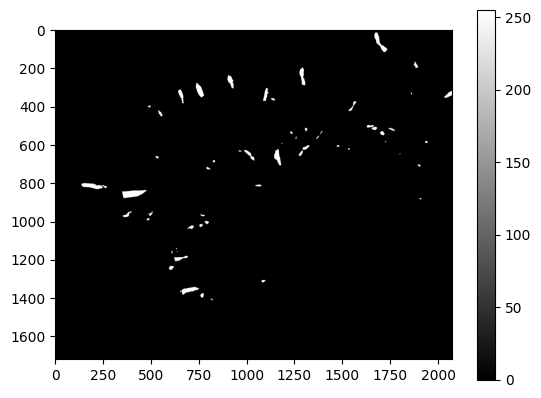

In [ ]:
plt.imshow(bin_im1_res1[0,:,:],cmap='gray')
plt.colorbar()

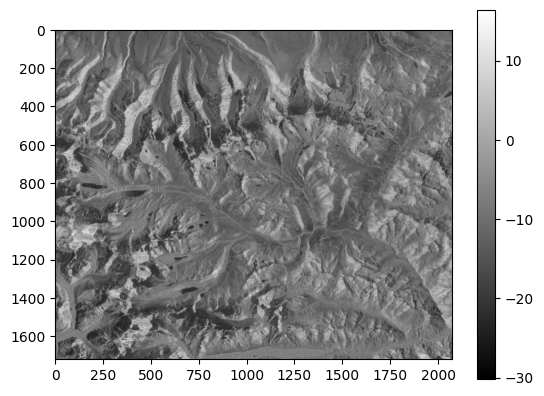

In [ ]:
plt.imshow(sent_im1_res1_reshape[:,:,0],cmap='gray')
plt.colorbar()

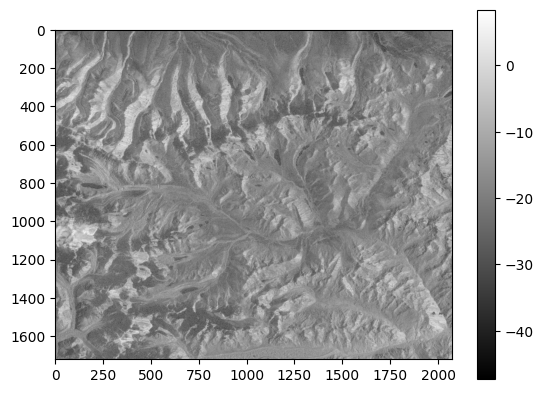

In [ ]:
plt.imshow(sent_im1_res1_reshape[:,:,1],cmap='gray')
plt.colorbar()

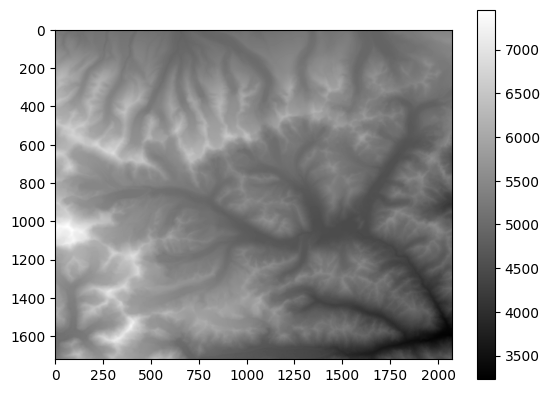

In [ ]:
plt.imshow(sent_im1_res1_reshape[:,:,2],cmap='gray')
plt.colorbar()

In [ ]:
patch_size=64
patchify(bin_im1_res1[0,:,:], (patch_size, patch_size), step=patch_size).shape

(26, 32, 64, 64)

In [ ]:
patch_size=64
bin_patch_im1_res1=patchify(bin_im1_res1[0,:,:], (patch_size, patch_size), step=patch_size)[:,:,:,:]
print('image of shape ',bin_im1_res1[0,:,:].shape,' patches into ',bin_patch_im1_res1.shape)

image of shape  (1721, 2072)  patches into  (26, 32, 64, 64)


In [ ]:
patchify(sent_im1_res1_reshape, (patch_size, patch_size, sent_im1_res1_reshape.shape[2]), step=patch_size).shape

(26, 32, 1, 64, 64, 3)

In [ ]:
sent_patch_im1_res1=patchify(sent_im1_res1_reshape, (patch_size, patch_size, sent_im1_res1_reshape.shape[2]), step=patch_size)[:,:,0,:,:,:]
print('image of shape ',sent_im1_res1_reshape.shape,' patched into ',sent_patch_im1_res1.shape)

image of shape  (1721, 2072, 3)  patched into  (26, 32, 64, 64, 3)


In [ ]:
for i in range(bin_patch_im1_res1.shape[0]):
    for j in range(bin_patch_im1_res1.shape[1]):
        if bin_patch_im1_res1[i, j, :, :].sum():
            # Save with filenames representing patch indices
            np.save(f'/content/drive/MyDrive/rashid_trials/bin/im_1_{i}_{j}.npy', bin_patch_im1_res1[i, j, :, :])
            np.save(f'/content/drive/MyDrive/rashid_trials/sent/im_1_{i}_{j}.npy', sent_patch_im1_res1[i, j, :, :, :])

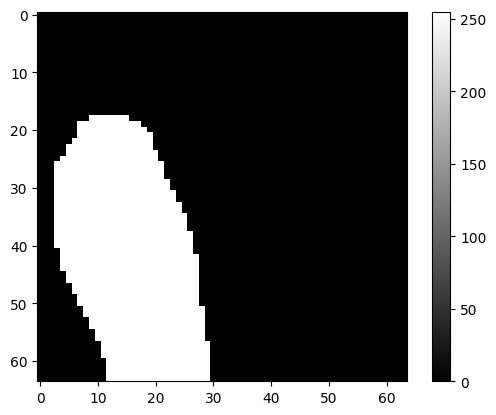

In [ ]:
plt.imshow(np.load('/content/drive/MyDrive/rashid_trials/bin/im_1_0_26.npy'),cmap='gray')
plt.colorbar()

In [ ]:
test=np.load('/content/drive/MyDrive/rashid_trials/sent/im_1_0_26.npy')
test.shape

(64, 64, 3)

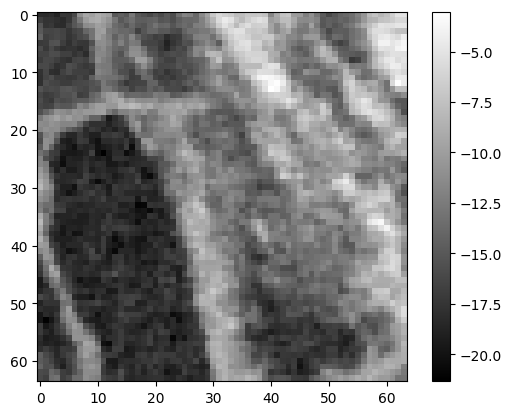

In [ ]:
plt.imshow(test[:,:,0],cmap='gray')
plt.colorbar()

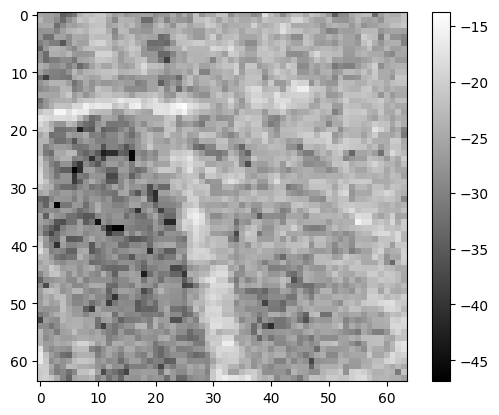

In [ ]:
plt.imshow(test[:,:,1],cmap='gray')
plt.colorbar()

In [ ]:
patch_size=64

In [ ]:
# Create an array of filenames with res as columns and im as rows
bin_var_arr=[[fn_bin_im1_res1,fn_bin_im1_res2,fn_bin_im1_res3,fn_bin_im1_res4],[fn_bin_im2_res1,fn_bin_im2_res2,fn_bin_im2_res3,fn_bin_im2_res4],[fn_bin_im3_res1,fn_bin_im3_res2,fn_bin_im3_res3,fn_bin_im3_res4],[fn_bin_im4_res1,fn_bin_im4_res2,fn_bin_im4_res3,fn_bin_im4_res4]]
vv_var_arr=[[fn_vv_im1_res1,fn_vv_im1_res2,fn_vv_im1_res3,fn_vv_im1_res4],[fn_vv_im2_res1,fn_vv_im2_res2,fn_vv_im2_res3,fn_vv_im2_res4],[fn_vv_im3_res1,fn_vv_im3_res2,fn_vv_im3_res3,fn_vv_im3_res4],[fn_vv_im4_res1,fn_vv_im4_res2,fn_vv_im4_res3,fn_vv_im4_res4]]
vh_var_arr=[[fn_vh_im1_res1,fn_vh_im1_res2,fn_vh_im1_res3,fn_vh_im1_res4],[fn_vh_im2_res1,fn_vh_im2_res2,fn_vh_im2_res3,fn_vh_im2_res4],[fn_vh_im3_res1,fn_vh_im3_res2,fn_vh_im3_res3,fn_vh_im3_res4],[fn_vh_im4_res1,fn_vh_im4_res2,fn_vh_im4_res3,fn_vh_im4_res4]]
dem_var_arr=[[fn_dem_im1_res1,fn_dem_im1_res2,fn_dem_im1_res3,fn_dem_im1_res4],[fn_dem_im2_res1,fn_dem_im2_res2,fn_dem_im2_res3,fn_dem_im2_res4],[fn_dem_im3_res1,fn_dem_im3_res2,fn_dem_im3_res3,fn_dem_im3_res4],[fn_dem_im4_res1,fn_dem_im4_res2,fn_dem_im4_res3,fn_dem_im4_res4]]

In [ ]:
import os

for i in range(4):
    for j in range(4):
        print('XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image ', i + 1, ' resolution ', j + 1, ' XXXXXXXXXXXXXXXXXXXXXXXXX')


        # Open binary image i with res j
        bin_im = rst.open(bin_var_arr[i][j]).read()

        # Set all accidental 20 values as 0
        bin_im[bin_im == 20] = 0

        # Open vv, vh, and dem image i with res j
        vv_im = rst.open(vv_var_arr[i][j]).read()
        vh_im = rst.open(vh_var_arr[i][j]).read()
        dem_im = rst.open(dem_var_arr[i][j]).read()

        # Stack vv, vh, and dem into a 3-band image and reshape using moveaxis
        if (vv_im.shape) != (vh_im.shape) or (vh_im.shape) != (dem_im.shape) or (vv_im.shape) != (dem_im.shape):
            new_shape_0 = min(vv_im.shape[0], vh_im.shape[0], dem_im.shape[0])
            new_shape_1 = min(vv_im.shape[1], vh_im.shape[1], dem_im.shape[1])
            new_shape_2 = min(vv_im.shape[2], vh_im.shape[2], dem_im.shape[2])
            vv_im = vv_im[:new_shape_0, :new_shape_1, :new_shape_2]
            vh_im = vh_im[:new_shape_0, :new_shape_1, :new_shape_2]
            dem_im = dem_im[:new_shape_0, :new_shape_1, :new_shape_2]
        sent_im = np.concatenate((vv_im, vh_im, dem_im), axis=0)
        sent_im_reshape = np.moveaxis(sent_im, 0, -1)

        # Generate patches using patchify
        bin_patch = patchify(bin_im[0, :, :], (patch_size, patch_size), step=patch_size)[:, :, :, :]
        sent_patch = patchify(sent_im_reshape, (patch_size, patch_size, sent_im_reshape.shape[2]), step=patch_size)[:, :, 0, :, :, :]

          # Create necessary directories before saving
        os.makedirs(f'/content/drive/MyDrive/rashid_trials/un/im{i + 1}', exist_ok=True)
        os.makedirs(f'/content/drive/MyDrive/rashid_trials/fil/bin/im{i + 1}/res{j + 1}', exist_ok=True)
        os.makedirs(f'/content/drive/MyDrive/rashid_trials/fil/en/im{i + 1}/res{j + 1}', exist_ok=True)

        # Write unfiltered patch numpys
        np.save(f'/content/drive/MyDrive/rashid_trials/un/im{i + 1}/res{j + 1}_bin.npy', bin_patch)
        np.save(f'/content/drive/MyDrive/rashid_trials/un/im{i + 1}/res{j + 1}_sent.npy', sent_patch)
        print('Written unfiltered patches')

        for k in range(bin_patch.shape[0]):
            for l in range(bin_patch.shape[1]):
                if bin_patch[k, l, :, :].sum():
                    # Save patches using their indices (k, l)
                    np.save(f'/content/drive/MyDrive/rashid_trials/fil/bin/im{i + 1}/res{j + 1}/patch_{k}_{l}.npy', bin_patch[k, l, :, :])
                    np.save(f'/content/drive/MyDrive/rashid_trials/fil/en/im{i + 1}/res{j + 1}/patch_{k}_{l}.npy', sent_patch[k, l, :, :, :])


XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  1  resolution  1  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patches based on indices
XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  1  resolution  2  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patches based on indices
XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  1  resolution  3  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patches based on indices
XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  1  resolution  4  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patches based on indices
XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  2  resolution  1  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patches based on indices
XXXXXXXXXXXXXXXXXXXXXXXXX Starting processing for image  2  resolution  2  XXXXXXXXXXXXXXXXXXXXXXXXX
Written unfiltered patches
Written filtered patch

In [ ]:
import os

tst = ['/content/drive/MyDrive/rashid_trials/fil/en/im1/res1',
       '/content/drive/MyDrive/rashid_trials/fil/en/im2/res1',
       '/content/drive/MyDrive/rashid_trials/fil/en/im3/res1',
       '/content/drive/MyDrive/rashid_trials/fil/en/im4/res1',
       '/content/drive/MyDrive/rashid_trials/fil/bin/im1/res1',
       '/content/drive/MyDrive/rashid_trials/fil/bin/im2/res1',
       '/content/drive/MyDrive/rashid_trials/fil/bin/im3/res1',
       '/content/drive/MyDrive/rashid_trials/fil/bin/im4/res1']

for i in tst:
  print(len(os.listdir(i)))

90
20
110
124
90
20
110
124


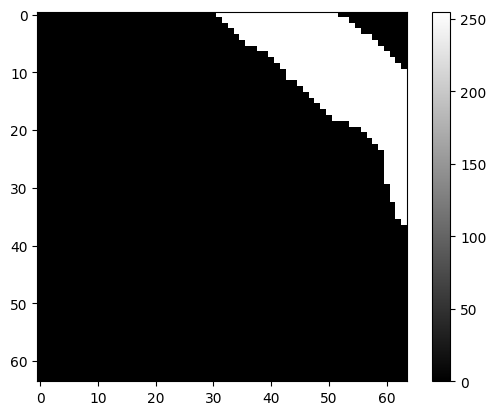

In [ ]:
plt.imshow(np.load('/content/drive/MyDrive/rashid_trials/fil/bin/im1/res1/patch_10_15.npy'),cmap='gray')
plt.colorbar()

In [ ]:
test=np.load('/content/drive/MyDrive/rashid_trials/fil/en/im1/res1/patch_10_15.npy')
test.shape

(64, 64, 3)

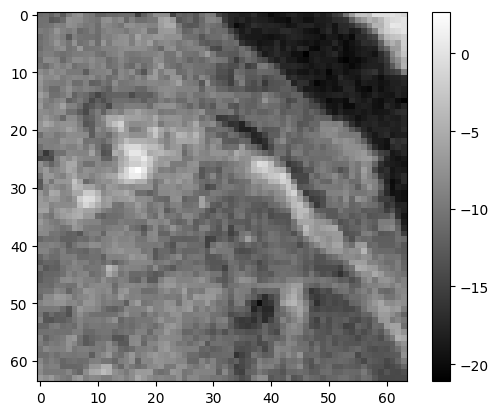

In [ ]:
plt.imshow(test[:,:,0],cmap='gray')
plt.colorbar()

#Timeseries(test for one file)[link text](https://)

In [ ]:
vv_2015='/content/drive/MyDrive/sentinel1_timeseries/s1_1vv_2018.tif'
vh_2015='/content/drive/MyDrive/sentinel1_timeseries/s1_1vh_2018.tif'
dem_im='/content/drive/MyDrive/timeseries/Dem/dem_1.tif'

In [ ]:
vv_im=rst.open(vv_2015).read()
vh_im=rst.open(vh_2015).read()
dem_im=rst.open(dem_im).read()

In [ ]:
sent_im=np.concatenate((vv_im,vh_im,dem_im),axis=0)
sent_im_reshape=np.moveaxis(sent_im,0,-1)
print('VV shape: ',vv_im.shape)
print('VH shape: ',vh_im.shape)
print('DEM shape: ',dem_im.shape)
print('stacked shape: ',sent_im.shape)
print('reshaped stacked shape: ',sent_im_reshape.shape)

VV shape:  (1, 2041, 2202)
VH shape:  (1, 2041, 2202)
DEM shape:  (1, 2041, 2202)
stacked shape:  (3, 2041, 2202)
reshaped stacked shape:  (2041, 2202, 3)


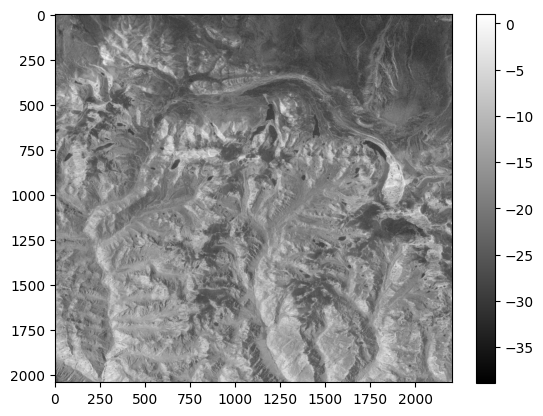

In [ ]:
plt.imshow(sent_im_reshape[:,:,1],cmap='gray')
plt.colorbar()

In [ ]:
patch_size = 64
sent_patch_im = patchify(sent_im_reshape, (patch_size, patch_size, sent_im_reshape.shape[2]), step=patch_size)[:,:,0,:,:,:]
print('image of shape ', sent_im_reshape.shape, ' patched into ', sent_patch_im.shape)
total_patches = sent_patch_im.shape[0] * sent_patch_im.shape[1]
print(f'Total number of patches created: {total_patches}')


image of shape  (2041, 2202, 3)  patched into  (31, 34, 64, 64, 3)
Total number of patches created: 1054


[link text](https:// [link text](https://))#Filtration

In [ ]:
for i in range(sent_patch_im.shape[0]): # Use .shape[0] to get the size of the first dimension
    for j in range(sent_patch_im.shape[1]): # Use .shape[1] to get the size of the second dimension
        np.save(f'/content/drive/MyDrive/rashid_trials/time/2018/unfil/im_4/patch_{i}_{j}.npy', sent_patch_im[i, j, :, :, :]) # Use sent_patch_im1 (not sent_patch_im1_res1)

# TIMESERIES FILTERATION

In [ ]:
unfil_dir = '/content/drive/MyDrive/rashid_trials/time/2018/unfil/im_4'
fil_dir = '/content/drive/MyDrive/rashid_trials/fil/bin/im4/res1'
output_dir = '/content/drive/MyDrive/rashid_trials/time/2018/fil/im_4'

os.makedirs(output_dir, exist_ok=True)
filtered_patches = {os.path.basename(f) for f in os.listdir(fil_dir)}
saved_patch_count = 0

# Filter and save matching patches from unfil
for patch in os.listdir(unfil_dir):
    if os.path.basename(patch) in filtered_patches:
        patch_data = np.load(os.path.join(unfil_dir, patch))
        np.save(os.path.join(output_dir, patch), patch_data)
        saved_patch_count += 1
print(f"Total patches saved: {saved_patch_count}")

Total patches saved: 124




```

```



# validity of data

In [ ]:
directory_paths = [f'/content/drive/MyDrive/rashid_trials/time/2023/fil/im_{i+1}' for i in range(4)]

expected_shape = (64, 64,3)
for directory_path in directory_paths:
    for filename in os.listdir(directory_path):
        filepath = os.path.join(directory_path, filename)
        data = np.load(filepath)
        if data.shape != expected_shape:
            print(f"Shape mismatch: {filename} in {directory_path} has shape {data.shape}")

# loop over for the processing of timeseries data

In [ ]:
# im_1 2024 file path
im_1_vv = '/content/drive/MyDrive/timeseries/2024/s1vv_2024.tif'
im_1_vh = '/content/drive/MyDrive/timeseries/2024/s1vh_2024.tif'
im_1_dem = '/content/drive/MyDrive/timeseries/Dem/dem.tif'

# im_2 2024 file path
im_2_vv = '/content/drive/MyDrive/timeseries/2024/s1_finvv_2024.tif'
im_2_vh = '/content/drive/MyDrive/timeseries/2024/s1_finvh_2024.tif'
im_2_dem ='/content/drive/MyDrive/timeseries/Dem/dem_fin.tif'

# im_3 2024 file path
im_3_vv = '/content/drive/MyDrive/timeseries/2024/s1_3vv_2024.tif'
im_3_vh = '/content/drive/MyDrive/timeseries/2024/s1_3vh_2024.tif'
im_3_dem = '/content/drive/MyDrive/timeseries/Dem/dem_3.tif'

# im_1 2024 file path
im_4_vv = '/content/drive/MyDrive/timeseries/2024/s1_1vv_2024.tif'
im_4_vh = '/content/drive/MyDrive/timeseries/2024/s1_1vh_2024.tif'
im_4_dem = '/content/drive/MyDrive/timeseries/Dem/dem_1.tif'

In [ ]:
im =[[im_1_vv,im_1_vh,im_1_dem],[im_2_vv,im_2_vh,im_2_dem],[im_3_vv,im_3_vh,im_3_dem],[im_4_vv,im_4_vh,im_4_dem]]

combination of files 1 has shape (1721, 2072, 3)
shape of vv band 1 is (1, 1721, 2072)
shape of vh band 1 is (1, 1721, 2072)
shape of dem band 1 is (1, 1721, 2072)


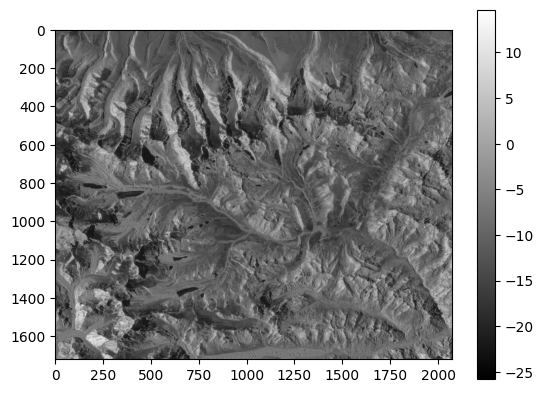

image of shape  (1721, 2072, 3)  patched into  (26, 32, 64, 64, 3)
Total number of patches created: 832
combination of files 2 has shape (1675, 2860, 3)
shape of vv band 2 is (1, 1675, 2860)
shape of vh band 2 is (1, 1675, 2860)
shape of dem band 2 is (1, 1675, 2860)


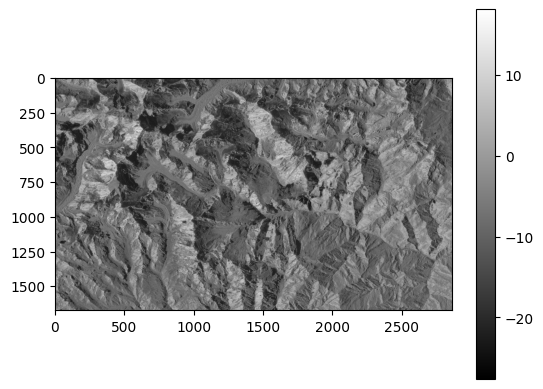

image of shape  (1675, 2860, 3)  patched into  (26, 44, 64, 64, 3)
Total number of patches created: 1144
combination of files 3 has shape (2543, 1645, 3)
shape of vv band 3 is (1, 2543, 1645)
shape of vh band 3 is (1, 2543, 1645)
shape of dem band 3 is (1, 2543, 1645)


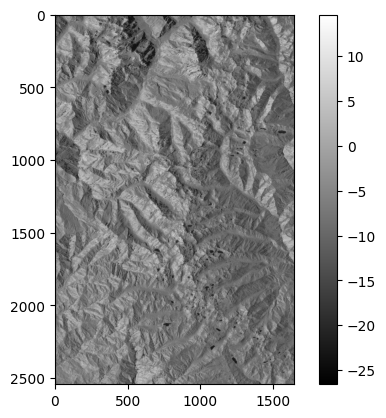

image of shape  (2543, 1645, 3)  patched into  (39, 25, 64, 64, 3)
Total number of patches created: 975
combination of files 4 has shape (2041, 2202, 3)
shape of vv band 4 is (1, 2041, 2202)
shape of vh band 4 is (1, 2041, 2202)
shape of dem band 4 is (1, 2041, 2202)


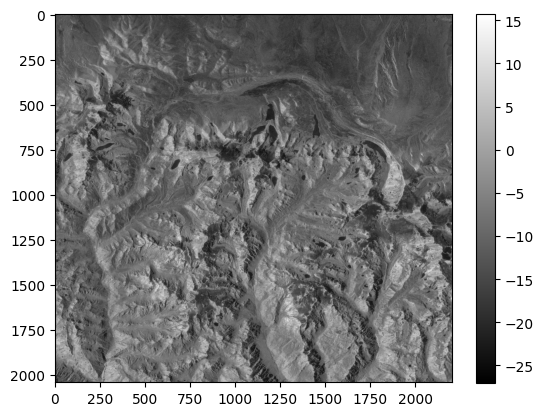

image of shape  (2041, 2202, 3)  patched into  (31, 34, 64, 64, 3)
Total number of patches created: 1054


In [ ]:
for i in range(len(im)):
  vv_im=rst.open(im[i][0]).read()
  vh_im=rst.open(im[i][1]).read()
  dem_im=rst.open(im[i][2]).read()

  sent_im=np.concatenate((vv_im,vh_im,dem_im),axis=0)
  sent_im_reshape=np.moveaxis(sent_im,0,-1)


  print(f'combination of files {i+1} has shape {sent_im_reshape.shape}')
  print(f'shape of vv band {i+1} is {vv_im.shape}')
  print(f'shape of vh band {i+1} is {vh_im.shape}')
  print(f'shape of dem band {i+1} is {dem_im.shape}')

  plt.imshow(sent_im_reshape[:,:,0],cmap='gray')
  plt.colorbar()
  plt.show()

  patch_size = 64
  sent_patch_im = patchify(sent_im_reshape, (patch_size, patch_size, sent_im_reshape.shape[2]), step=patch_size)[:,:,0,:,:,:]
  print('image of shape ', sent_im_reshape.shape, ' patched into ', sent_patch_im.shape)
  total_patches = sent_patch_im.shape[0] * sent_patch_im.shape[1]
  print(f'Total number of patches created: {total_patches}')


  os.makedirs(f'/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im{i + 1}', exist_ok=True)
  os.makedirs(f'/content/drive/MyDrive/rashid_trials/time/2024/filtered/im{i + 1}', exist_ok=True)


  for k in range(sent_patch_im.shape[0]):
      for l in range(sent_patch_im.shape[1]):
          np.save(f'/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im{i + 1}/patch_{k}_{l}.npy', sent_patch_im[k, l, :, :, :])




# number of unfiltered patches saved

In [ ]:
for i in range(len(os.listdir('/content/drive/MyDrive/rashid_trials/time/2024/unfiltered'))):
  x= len(os.listdir(f'/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im{i + 1}'))
  print(f'number of files in im{i + 1} is {x}')


number of files in im1 is 832
number of files in im2 is 1144
number of files in im3 is 975
number of files in im4 is 1054


# loop over filteration part for the time series data

In [ ]:
unfil_dirs = [
 '/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im1',
 '/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im2',
 '/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im3',
 '/content/drive/MyDrive/rashid_trials/time/2024/unfiltered/im4'
]

fil_dirs = [
    '/content/drive/MyDrive/rashid_trials/fil/bin/im1/res1',
    '/content/drive/MyDrive/rashid_trials/fil/bin/im2/res1',
    '/content/drive/MyDrive/rashid_trials/fil/bin/im3/res1',
    '/content/drive/MyDrive/rashid_trials/fil/bin/im4/res1'
]

output_dirs = [
 '/content/drive/MyDrive/rashid_trials/time/2024/filtered/im1',
 '/content/drive/MyDrive/rashid_trials/time/2024/filtered/im2',
 '/content/drive/MyDrive/rashid_trials/time/2024/filtered/im3',
 '/content/drive/MyDrive/rashid_trials/time/2024/filtered/im4'
]


for i in range(len(unfil_dirs)):
  unfil_dir = unfil_dirs[i]
  fil_dir = fil_dirs[i]
  output_dir = output_dirs[i]

  os.makedirs(output_dir, exist_ok=True)
  filtered_patches = {os.path.basename(f) for f in os.listdir(fil_dir)}
  saved_patch_count = 0

  for patch in os.listdir(unfil_dir):
      if os.path.basename(patch) in filtered_patches:
          patch_data = np.load(os.path.join(unfil_dir, patch))
          np.save(os.path.join(output_dir, patch), patch_data)
          saved_patch_count += 1
  print(f"{output_dirs[i]}Total patches saved: {saved_patch_count}")

/content/drive/MyDrive/rashid_trials/time/2024/filtered/im1Total patches saved: 90
/content/drive/MyDrive/rashid_trials/time/2024/filtered/im2Total patches saved: 20
/content/drive/MyDrive/rashid_trials/time/2024/filtered/im3Total patches saved: 110
/content/drive/MyDrive/rashid_trials/time/2024/filtered/im4Total patches saved: 124


# FILTRATION FOR BINARY

In [ ]:
import os
import numpy as np
import shutil


input_dir = "/content/drive/MyDrive/rashid_trials/fil/bin/im1"
output_dir = "/content/drive/MyDrive/summit"


os.makedirs(output_dir, exist_ok=True)

saved_count = 0


for file in os.listdir(input_dir):
    if file.endswith(".npy"):
        file_path = os.path.join(input_dir, file)


        patch = np.load(file_path)

        if patch.sum():
            shutil.copy(file_path, os.path.join(output_dir, file))
            saved_count += 1

print(f" Total glacier lake patches saved: {saved_count}")


 Total glacier lake patches saved: 0


In [ ]:
len(os.listdir("/content/drive/MyDrive/summit"))

90